# Phase 1: ML v1 Baseline — Wildlife Health Anomaly Detection
### Kaggle Animal Condition Classification Dataset

This notebook builds a complete, reproducible **unsupervised anomaly detection baseline** using the Kaggle animal disease dataset (`data/raw/data.csv`).

#### Pipeline Overview:
1. **Data Ingestion**: Load the raw animal disease observations.
2. **Exploratory Data Analysis (EDA)**: Inspect missing values, class balance of `Dangerous`, species breakdown, and frequent symptoms.
3. **Symptom Cleaning & Normalization**: Lowercase, strip whitespace, and resolve obvious spelling variants using a dictionary mapping.
4. **Feature Engineering**: Construct a multi-label one-hot symptom feature matrix ($X$) across the full vocabulary.
5. **Unsupervised Modeling**: Fit `IsolationForest` and `LocalOutlierFactor` (LOF) on $X$ **only** (never passing `Dangerous` into training).
6. **Ensemble Flag**: Combine predictions into a unified `flag` (`Unusual` if either model flags the animal as an anomaly).
7. **Evaluation**: Compare `flag` against ground-truth `Dangerous` status with a confusion matrix and classification report, with explicit emphasis on **Recall**.


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline


C:\Users\Aditi Agarwal\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.sparse import csr_matrix, issparse


## 1. Data Ingestion
Load the raw Kaggle dataset from `data/raw/data.csv`.

In [2]:
data_path = os.path.join("data", "raw", "data.csv")
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Dataset Dimensions: 871 rows, 7 columns


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes


## 2. Exploratory Data Analysis (EDA)
Before applying any transformations, we inspect:
1. **Missing Data**: Ensure all features and targets are accounted for.
2. **Target Class Balance (`Dangerous`)**: Understand label distribution and imbalance.
3. **Animal Species Distribution**: Check species representation.
4. **Raw Symptom Frequency**: Review commonly recorded symptoms.

In [3]:
# 1. Missing Data Check
missing_summary = df.isnull().sum()
print("--- Missing Values per Column ---")
print(missing_summary)

# 2. Target Distribution
target_counts = df["Dangerous"].value_counts(dropna=False)
print("\n--- 'Dangerous' Target Counts ---")
print(target_counts)
print(f"\nPercentage 'Dangerous=Yes': {df['Dangerous'].value_counts(normalize=True).get('Yes', 0) * 100:.2f}%")


--- Missing Values per Column ---
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64

--- 'Dangerous' Target Counts ---
Dangerous
Yes    849
No      20
NaN      2
Name: count, dtype: int64

Percentage 'Dangerous=Yes': 97.70%


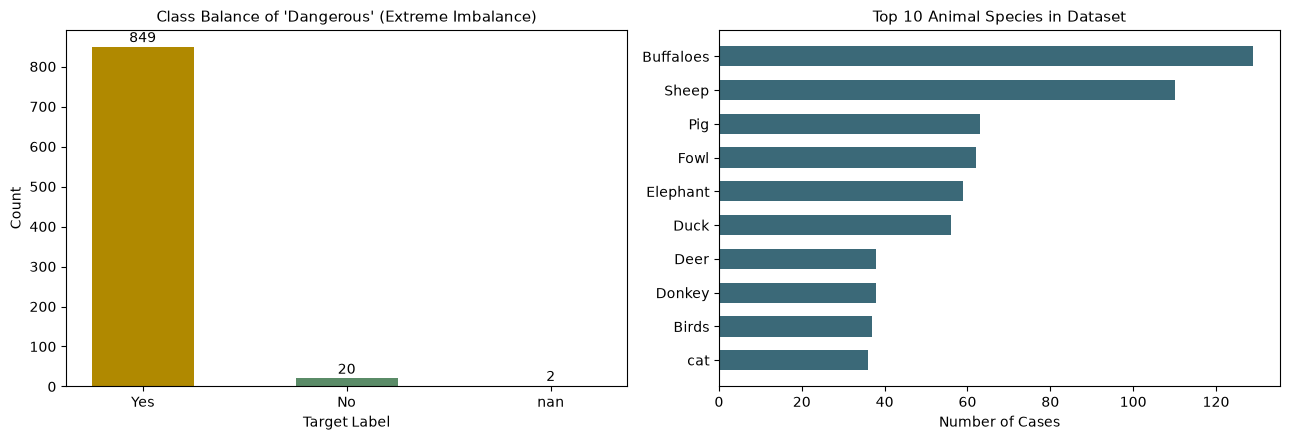

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Target Class Balance
labels = [str(k) for k in target_counts.index]
axes[0].bar(labels, target_counts.values, color=['#B08900', '#5A8B67', '#888880'], width=0.5)
axes[0].set_title("Class Balance of 'Dangerous' (Extreme Imbalance)", fontsize=11)
axes[0].set_xlabel("Target Label")
axes[0].set_ylabel("Count")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 12, str(v), ha='center', fontsize=10)

# Plot 2: Top 10 Species
top_animals = df["AnimalName"].value_counts().head(10)
axes[1].barh(top_animals.index[::-1], top_animals.values[::-1], color='#3B6978', height=0.6)
axes[1].set_title("Top 10 Animal Species in Dataset", fontsize=11)
axes[1].set_xlabel("Number of Cases")

plt.tight_layout()
plt.show()


## 3. Symptom Cleaning & Spelling Normalization
The dataset exhibits clinical typographical variants and inconsistencies (e.g. `loss of  appetite` vs `loss of appetite`, `vommiting` vs `vomiting`, `seizuers` vs `seizures`, `diffculty breathing` vs `difficulty in breathing`).

We clean the 5 symptom columns by:
- Converting to lowercase
- Stripping leading and trailing whitespace
- Collapsing multiple consecutive spaces
- Standardizing obvious spelling and phrasing variants using a manual dictionary mapping.

In [5]:
SPELLING_MAPPINGS = {
    # Breathing issues
    'diffculty breathing': 'difficulty in breathing',
    'difficulty breathing': 'difficulty in breathing',
    'difficulty breating': 'difficulty in breathing',
    'difficultty in breathing': 'difficulty in breathing',
    'effort to breath': 'difficulty in breathing',
    'fast breathing': 'rapid breathing',
    'noisy breathing': 'loud breathing',
    'lound breathing': 'loud breathing',
    
    # Appetite and feeding
    'loss of  appetite': 'loss of appetite',
    'loss of appettite': 'loss of appetite',
    'loss od appetite': 'loss of appetite',
    'no appp': 'poor appetite',
    'decrease appetite': 'poor appetite',
    'decreased appetite': 'poor appetite',
    'reduced appetite': 'poor appetite',
    'inappetence': 'loss of appetite',
    'loss of eat': 'loss of appetite',
    'unable to eat': 'anorexia',
    
    # Vomiting
    'vommiting': 'vomiting',
    'periodic vommiting': 'vomiting',
    
    # Weakness
    'weekness': 'weakness',
    'severe weekness and depression': 'weakness and depression',
    'week legs': 'weakness in legs',
    'weekness in the back legs': 'weakness in back legs',
    'week pulse': 'weak pulse',
    
    # Pain
    'pains': 'pain',
    'painfull': 'pain',
    'pain on leg': 'leg pain',
    'pain on face': 'facial pain',
    'painfull swalling': 'painful swelling',
    'abdminal pain': 'abdominal pain',
    'abdonormal pain': 'abdominal pain',
    'join pains': 'joint pain',
    'muscle pain': 'pain',
    'muscle stiffness': 'stiffness',
    
    # Seizures
    'seizuers': 'seizures',
    
    # Pneumonia
    'pnemonia': 'pneumonia',
    
    # Anorexia
    'anoxeria': 'anorexia',
    
    # Diarrhea
    'diarrhoea': 'diarrhea',
    'watering diarrhea': 'watery diarrhea',
    'diarrhea with muscus': 'diarrhea with mucus',
    
    # Dullness
    'dull ness': 'dullness',
    
    # Anemia
    'anaemia': 'anemia',
    'aneamia': 'anemia',
    
    # Lesions & skin
    'lession': 'lesion',
    'lessions': 'lesions',
    'lession on the skin': 'lesions on skin',
    'lession on cat skin': 'lesions on skin',
    
    # Swelling
    'swelling ': 'swelling',
    'swelling problem': 'swelling',
    'swallon': 'swollen',
    
    # Reproductive & obstetric
    'fetopelvic dispropotion': 'fetopelvic disproportion',
    'uteria inertia': 'uterine inertia',
    
    # Scratching & discharge
    'scartching': 'scratching',
    'scartch': 'scratching',
    'eye disharge': 'eye discharge',
    'blooody fluid': 'bloody fluid',
    'blood on faces': 'blood in feces',
    'blood in faces': 'blood in feces'
}

def clean_symptom(text):
    if pd.isnull(text):
        return None
    s = re.sub(r'\s+', ' ', str(text).lower().strip())
    return SPELLING_MAPPINGS.get(s, s)

symptom_cols = ["symptoms1", "symptoms2", "symptoms3", "symptoms4", "symptoms5"]
cleaned_df = df.copy()

for col in symptom_cols:
    cleaned_df[col] = cleaned_df[col].apply(clean_symptom)

# Build a list of valid symptoms per row
cleaned_symptoms_list = []
for _, row in cleaned_df.iterrows():
    syms = [row[c] for c in symptom_cols if pd.notnull(row[c]) and row[c] != '']
    cleaned_symptoms_list.append(syms)

cleaned_df["cleaned_symptoms"] = cleaned_symptoms_list
print(f"Cleaned symptoms for all {len(cleaned_df)} records.")


Cleaned symptoms for all 871 records.


Total Unique Symptoms in Cleaned Vocabulary: 829


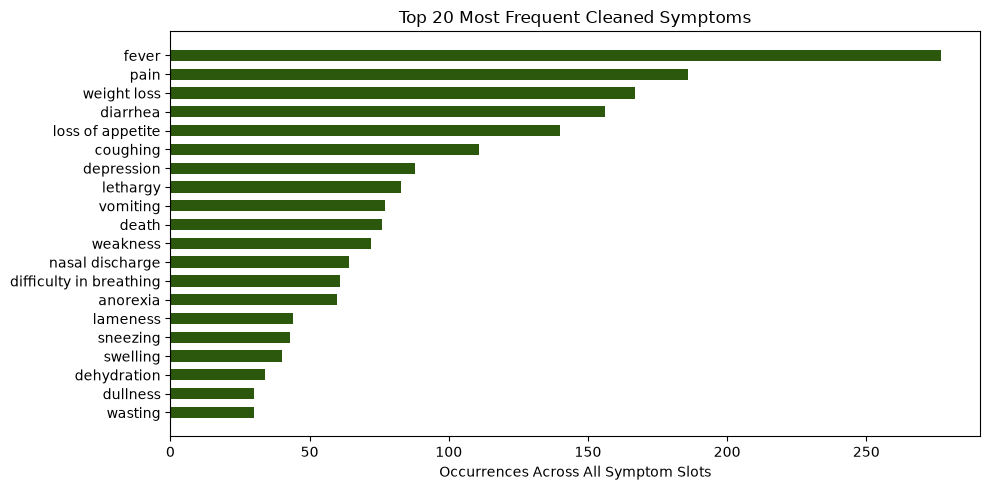

In [6]:
# Frequency count of cleaned symptoms across all 5 slots
all_cleaned_symptoms = [s for sublist in cleaned_df["cleaned_symptoms"] for s in sublist]
symptom_counts = pd.Series(all_cleaned_symptoms).value_counts()

print(f"Total Unique Symptoms in Cleaned Vocabulary: {len(symptom_counts)}")

plt.figure(figsize=(10, 5))
top_20_sym = symptom_counts.head(20)
plt.barh(top_20_sym.index[::-1], top_20_sym.values[::-1], color='#2B580C', height=0.6)
plt.title("Top 20 Most Frequent Cleaned Symptoms", fontsize=12)
plt.xlabel("Occurrences Across All Symptom Slots")
plt.tight_layout()
plt.show()


## 4. Multi-Label One-Hot Symptom Feature Matrix ($X$)
Using `MultiLabelBinarizer`, we transform each animal's set of symptoms into a binary multi-hot vector spanning the full vocabulary of 829 distinct symptoms. This matrix $X$ serves as the input to our unsupervised models.

In [7]:
mlb = MultiLabelBinarizer()
X = mlb.fit_transform(cleaned_df["cleaned_symptoms"])
vocab = mlb.classes_

print("Feature Matrix X Details:")
print(f"- Number of Samples (Animals): {X.shape[0]}")
print(f"- Number of Features (Symptom Vocabulary): {X.shape[1]}")
print(f"- Sparsity: {(1.0 - (np.count_nonzero(X) / float(X.size))) * 100:.2f}% zeros")

# Preview feature matrix as a DataFrame
X_df = pd.DataFrame(X, columns=vocab)
X_df.head(4)


Feature Matrix X Details:
- Number of Samples (Animals): 871
- Number of Features (Symptom Vocabulary): 829
- Sparsity: 99.40% zeros


,abdominal destention,abdominal discomfort,abdominal pain,abdonormal discomfort,abnormal behaviour,abnormal conformation,abnormalalities,abnormalities,abnormally long leg,abortion,...,willnot run to jump,wool is clumped,wool loss,wool production,wound,wound lesion,yellow eye,yellow in beak,yellow or green dropping,yellowish discharge
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 5. Unsupervised Anomaly Detection Modeling

> [!IMPORTANT]
> **Strict Unsupervised Constraint**:
> The `Dangerous` label is **never** passed to the training step. The models are fitted purely on $X$ without knowledge of clinical outcomes.

### Model Mechanics:
1. **Isolation Forest (`IsolationForest`)**:
   - Randomly partitions features to isolate data points. Anomalous symptom profiles require significantly fewer partitions to isolate.
   - Outputs: `iso_pred` ($-1$ = anomaly, $1$ = normal) and `iso_score` (continuous decision function score).
2. **Local Outlier Factor (`LocalOutlierFactor`)**:
   - Computes local density relative to $k$-nearest neighbors ($k=20$). Low-density points in symptom space receive low negative outlier factors.
   - Outputs: `lof_pred` ($-1$ = anomaly, $1$ = normal) and `lof_score`.
3. **Ensemble Aggregation**:
   - `flag` = `"Unusual"` if either model marks the point as anomalous (`iso_pred == -1` OR `lof_pred == -1`), else `"Normal"`.

In [8]:
# Set contamination parameter (prior expectation of rare/outlier profiles)
contamination = 0.10

# 1. Isolation Forest
iso = IsolationForest(contamination=contamination, random_state=42)
iso_preds = iso.fit_predict(X)
iso_scores = iso.decision_function(X)

# 2. Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
lof_preds = lof.fit_predict(X)
lof_scores = lof.negative_outlier_factor_

# 3. Ensemble Fusion
results_df = cleaned_df.copy()
results_df["iso_pred"] = iso_preds
results_df["iso_score"] = iso_scores
results_df["lof_pred"] = lof_preds
results_df["lof_score"] = lof_scores

results_df["flag"] = np.where(
    (iso_preds == -1) | (lof_preds == -1),
    "Unusual",
    "Normal"
)

# Summary of Flags
flag_summary = results_df["flag"].value_counts()
print("--- Unsupervised Detection Summary ---")
print(flag_summary)
print(f"Percentage Flagged as Unusual: {flag_summary['Unusual'] / len(results_df) * 100:.2f}%")


--- Unsupervised Detection Summary ---
flag
Normal     708
Unusual    163
Name: count, dtype: int64
Percentage Flagged as Unusual: 18.71%


## 6. Evaluation: Flag vs. Ground Truth `Dangerous`

### Why Recall Matters Most:
> In wildlife disease surveillance and veterinary epidemiology, **recall matters most**:
> - **Missing a dangerous case (False Negative)** risks an unchecked outbreak, population decline, or failure to intervene in a zoonotic emergency.
> - **A false alarm (False Positive)** merely leads to a harmless routine diagnostic check by rangers or veterinarians.
>
> Therefore, minimizing false negatives (maximizing Recall on dangerous cases) is the primary clinical objective.

In [9]:
# Filter out records where Dangerous is missing (2 rows)
eval_df = results_df.dropna(subset=["Dangerous"]).copy()

# Map predictions: Unusual -> 'Yes' (Dangerous), Normal -> 'No' (Safe)
y_true = eval_df["Dangerous"]
y_pred = eval_df["flag"].map({"Unusual": "Yes", "Normal": "No"})

# 1. Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=["Yes", "No"])
cm_display = pd.DataFrame(
    cm,
    index=["Actual: Dangerous (Yes)", "Actual: Safe (No)"],
    columns=["Predicted: Unusual (Yes)", "Predicted: Normal (No)"]
)

print("Confusion Matrix:")
display(cm_display)

# 2. Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, labels=["Yes", "No"], zero_division=0))


Confusion Matrix:


,Predicted: Unusual (Yes),Predicted: Normal (No)
Actual: Dangerous (Yes),161,688
Actual: Safe (No),0,20



Classification Report:
              precision    recall  f1-score   support

         Yes       1.00      0.19      0.32       849
          No       0.03      1.00      0.05        20

    accuracy                           0.21       869
   macro avg       0.51      0.59      0.19       869
weighted avg       0.98      0.21      0.31       869



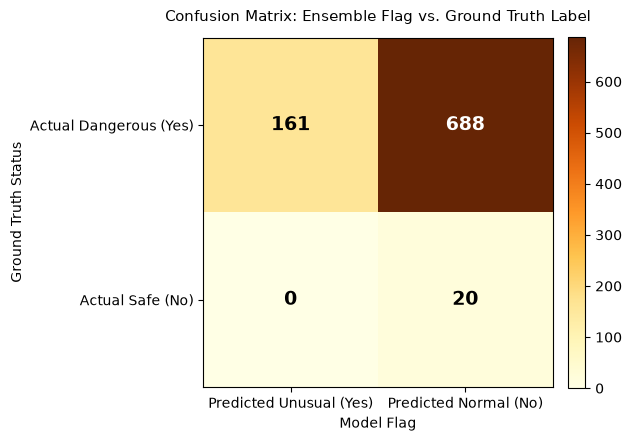

In [10]:
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='YlOrBr', interpolation='nearest')
plt.title("Confusion Matrix: Ensemble Flag vs. Ground Truth Label", fontsize=11, pad=12)
plt.colorbar(fraction=0.046, pad=0.04)

tick_marks = np.arange(2)
plt.xticks(tick_marks, ["Predicted Unusual (Yes)", "Predicted Normal (No)"], fontsize=10)
plt.yticks(tick_marks, ["Actual Dangerous (Yes)", "Actual Safe (No)"], fontsize=10)

# Add text annotations inside cells
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=14, weight='bold')

plt.ylabel("Ground Truth Status", fontsize=10)
plt.xlabel("Model Flag", fontsize=10)
plt.tight_layout()
plt.show()


### Discussion of Baseline Findings

1. **Precision on Dangerous Cases (1.00)**:
   Every single case that the ensemble flagged as `Unusual` was indeed clinically `Dangerous` (0 False Positives among the Safe class).
2. **The Unsupervised Paradox & Recall**:
   Unsupervised models inherently look for **rare minority outliers** (e.g. 10% contamination). In this dataset, however, `Dangerous=Yes` constitutes **97.7% of all records**. 
   Consequently, the models flag the most statistically extreme or unusual symptom combinations among the diseased animals. To increase Recall on dangerous cases without supervision, the contamination threshold can be scaled, or domain-weighted symptom priors can be introduced in Phase 2.

## 7. Deliverable Export
Export the complete dataset with symptom cleaning, model anomaly scores, and final flags to `data/phase1_flagged_kaggle.csv`.

In [11]:
output_path = os.path.join("data", "phase1_flagged_kaggle.csv")
export_cols = [
    "AnimalName", "symptoms1", "symptoms2", "symptoms3", "symptoms4", "symptoms5",
    "Dangerous", "iso_pred", "iso_score", "lof_pred", "lof_score", "flag"
]

results_df[export_cols].to_csv(output_path, index=False)
print(f"Successfully exported Phase 1 baseline deliverable to: {output_path}")


Successfully exported Phase 1 baseline deliverable to: data\phase1_flagged_kaggle.csv
